# Stochastic modeling
The goal of this simulation is to use probability theory and Gilespie's algorithm to make all our deterministic ODEs into stochastic models in order to account for the randomness in biology.



Final protein (t = 180 min)
  nuc1  ODE   12134.7 | SSA   12153.0 +/- 101.1
  dspB  ODE    9833.1 | SSA    9837.6 +/- 66.5
  dspb_y ODE    8627.5 | SSA    8604.0 +/- 68.7
  sspA  ODE   10408.1 | SSA   10432.0 +/- 81.5


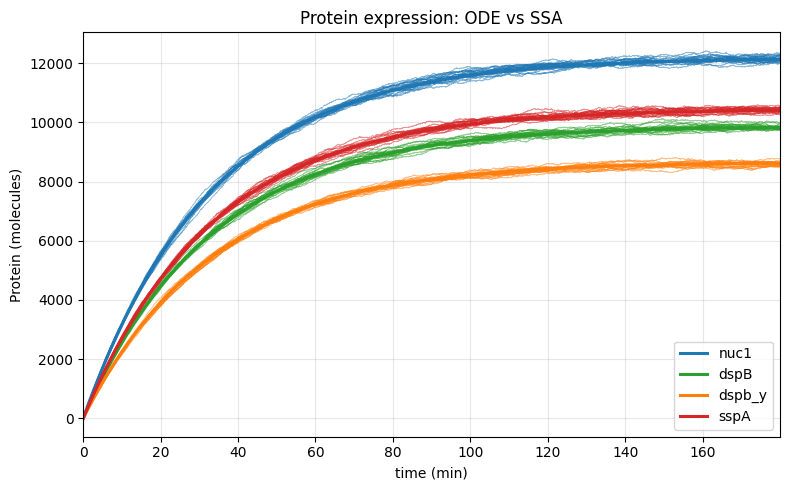

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
genes = ['nuc1', 'dspB', 'dspb_y','sspA']
k_syn = np.array([365.691, 296.33, 260, 313.66])  # protein synthesis (copies/min)
gamma = np.array([0.03, 0.03, 0.03, 0.03])   # protein decay (1/min)

time_total = 180
delta_t    = 0.01
time_vec   = np.arange(0, time_total, delta_t)
n_step     = time_vec.size
n_runs     = 20

# Compute deterministic equations
prot_det = np.zeros((len(genes), n_step))
for i in range(n_step - 1):
    dp = k_syn - gamma * prot_det[:, i]
    prot_det[:, i+1] = prot_det[:, i] + dp * delta_t

# Define Gillespie function and run Stochastic simulations
def gillespie(t_stop=time_total, max_step=2_000_000, seed=None):
    rng = np.random.default_rng(seed)
    t = 0.0
    x = np.zeros(len(genes))

    t_vals = [t]
    x_vals = [x.copy()]

    for _ in range(max_step):
        a  = np.concatenate([k_syn, gamma * x])
        a0 = a.sum()
        if a0 <= 0:
            break

        t += rng.exponential(1.0 / a0)
        if t > t_stop:
            break

        j = np.searchsorted(np.cumsum(a), rng.random() * a0)
        block, g = divmod(j, len(genes))
        if block == 0: x[g] += 1
        else:          x[g] -= 1

        x = np.maximum(x, 0)

        t_vals.append(t)
        x_vals.append(x.copy())

    return np.array(t_vals), np.array(x_vals).T


def to_grid(t_vals, y_vals, grid):
    idx = np.searchsorted(t_vals, grid, side='right') - 1
    return y_vals[..., np.clip(idx, 0, y_vals.shape[-1] - 1)]

prot_ens = np.empty((n_runs, len(genes), n_step))
for k in range(n_runs):
    t_s, x_s = gillespie(seed=k)
    prot_ens[k] = to_grid(t_s, x_s, time_vec)

prot_mean = prot_ens.mean(axis=0)
prot_sd   = prot_ens.std(axis=0)

print("\nFinal protein (t = 180 min)")
for g, name in enumerate(genes):
    print(f"  {name:5s} ODE {prot_det[g,-1]:9.1f} | "
          f"SSA {prot_mean[g,-1]:9.1f} +/- {prot_sd[g,-1]:.1f}")

# Plot all results
colors = ['tab:blue', 'tab:green', 'tab:orange','tab:red']
fig, ax = plt.subplots(figsize=(8, 5))
for g, name in enumerate(genes):
    c = colors[g]
    ax.plot(time_vec, prot_ens[:, g, :].T, color=c, lw=0.6, alpha=0.5)
    ax.plot(time_vec, prot_mean[g], color=c, lw=1.6, ls='--')
    ax.plot(time_vec, prot_det[g],  color=c, lw=2.2, label=name)
ax.set(xlabel='time (min)', ylabel='Protein (molecules)',
       title='Protein expression: ODE vs SSA')
ax.legend(fontsize=10, loc='lower right')
ax.margins(x=0)
fig.tight_layout()
plt.grid(alpha = 0.3)
plt.show()

Final Nuc1 protein count (deterministic): 12134.64 copies


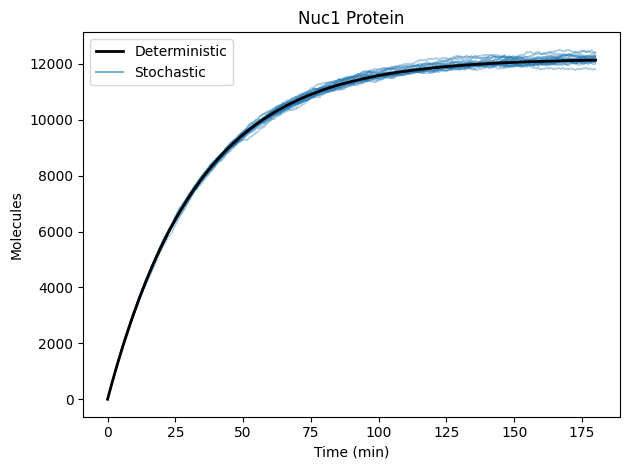

In [ ]:
# Code for Nuc1

import numpy as np
import matplotlib.pyplot as plt

# ---- Parameters ----
k_syn_nuc1 = 365.69
gamma_nuc1 = 0.03

# ---- Deterministic (Euler) ----
time = 180
delta_t = 0.01
time_vec = np.arange(0, time, delta_t)
n_step = np.size(time_vec)

nuc1 = np.zeros(n_step)

for i in range(n_step - 1):
  dnuc1_dt = k_syn_nuc1 - gamma_nuc1*nuc1[i]

  nuc1[i+1] = nuc1[i] + dnuc1_dt*delta_t

print(f"Final Nuc1 protein count (deterministic): {np.round(nuc1[n_step-1],2)} copies")

# ---- Stochastic (Gillespie) ----
def gillespie(nuc1_prot=0, max_step=500000, t_stop=time):
  t = 0
  prot_nuc1 = nuc1_prot

  t_vals   = [t]
  prot_vals = [prot_nuc1]

  for step in range(max_step):
    a1 = k_syn_nuc1
    a2 = gamma_nuc1*prot_nuc1
    a  = [a1, a2]
    a0 = np.sum(a)

    if a0 == 0:
      break

    # Create two random numbers and update time using tau
    # One random number decides when said reaction will occur
    # The other random number decides which reaction will occur next
    r1 = np.random.rand()
    r2 = np.random.rand()
    tau = -np.log(r1)/a0
    t += tau
    if t > t_stop:      # stop at the same window as the ODE
      break
    t_vals.append(t)

    r_mod = r2*a0
    next_reaction_idx = -1
    cumulative_rate = 0
    for i, ai in enumerate(a):
      cumulative_rate += ai
      if r_mod < cumulative_rate:
        next_reaction_idx = i
        break

    if next_reaction_idx == 0:
      prot_nuc1 += 1
    elif next_reaction_idx == 1:
      prot_nuc1 -= 1

    prot_nuc1 = max(prot_nuc1, 0)

    prot_vals.append(prot_nuc1)

  return t_vals, prot_vals

# ---- Run Gillespie and overlay on the deterministic solution ----
runs = 20

for i in range(runs):
  t_vals, prot_vals = gillespie()
  plt.plot(t_vals, prot_vals, color='tab:blue', alpha=0.35, lw=0.8)

# Deterministic curves on top (bold black)
plt.plot(time_vec, nuc1, 'k', lw=2, label='Deterministic')

# Proxy handles so the legend labels the stochastic runs
plt.plot([], [], color='tab:blue', alpha=0.6, label='Stochastic')
plt.title('Nuc1 Protein'); plt.xlabel('Time (min)'); plt.ylabel('Molecules'); plt.legend()

plt.tight_layout()
plt.show()

Final dspB protein count (deterministic): 9522.99 copies


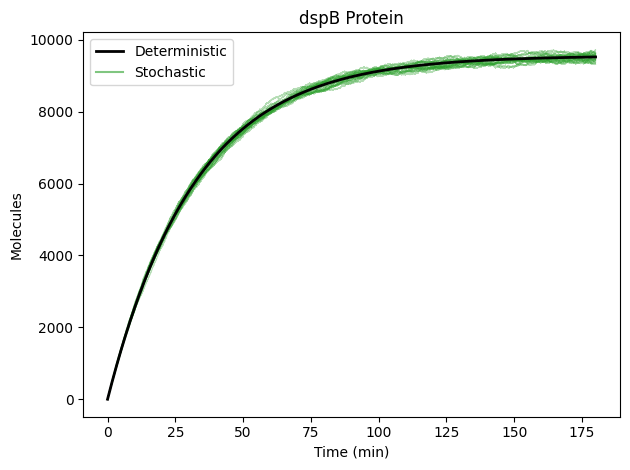

In [ ]:
# Code for dspB
import numpy as np
import matplotlib.pyplot as plt

# ---- Parameters ----
k_syn_dspB = 296.33
gamma_dspB = 0.031

# ---- Deterministic (Euler) ----
time = 180
delta_t = 0.01
time_vec = np.arange(0, time, delta_t)
n_step = np.size(time_vec)

dspB = np.zeros(n_step)

for i in range(n_step - 1):

  ddspB_dt = k_syn_dspB - gamma_dspB*dspB[i]

  dspB[i+1] = dspB[i] + ddspB_dt*delta_t
print(f"Final dspB protein count (deterministic): {np.round(dspB[n_step-1],2)} copies")

# ---- Stochastic (Gillespie) ----
def gillespie(dspb_prot=0, max_step=500000, t_stop=time):
  t = 0
  prot_dspb = dspb_prot

  t_vals   = [t]
  prot_vals = [prot_dspb]

  for step in range(max_step):
    a1 = k_syn_dspB
    a2 = gamma_dspB*prot_dspb
    a  = [a1, a2]
    a0 = np.sum(a)

    if a0 == 0:
      break

    r1 = np.random.rand()
    r2 = np.random.rand()
    tau = -np.log(r1)/a0
    t += tau
    if t > t_stop:
      break
    t_vals.append(t)

    r_mod = r2*a0
    next_reaction_idx = -1
    cumulative_rate = 0
    for i, ai in enumerate(a):
      cumulative_rate += ai
      if r_mod < cumulative_rate:
        next_reaction_idx = i
        break

    if next_reaction_idx == 0:
      prot_dspb += 1
    elif next_reaction_idx == 1:
      prot_dspb -= 1

    prot_dspb = max(prot_dspb, 0)

    prot_vals.append(prot_dspb)

  return t_vals, prot_vals

# ---- Run Gillespie and overlay on the deterministic solution ----
runs = 20

for i in range(runs):
  t_vals, prot_vals = gillespie()
  plt.plot(t_vals, prot_vals, color='tab:green', alpha=0.35, lw=0.8)

# Deterministic curves on top (bold black)
plt.plot(time_vec, dspB, 'k', lw=2, label='Deterministic')

# Proxy handles so the legend labels the stochastic runs
plt.plot([], [], color='tab:green', alpha=0.6, label='Stochastic')
plt.title('dspB Protein')
plt.xlabel('Time (min)')
plt.ylabel('Molecules')
plt.legend()
plt.tight_layout()
plt.show()

Final dspB_y protein count (deterministic): 8355.47 copies


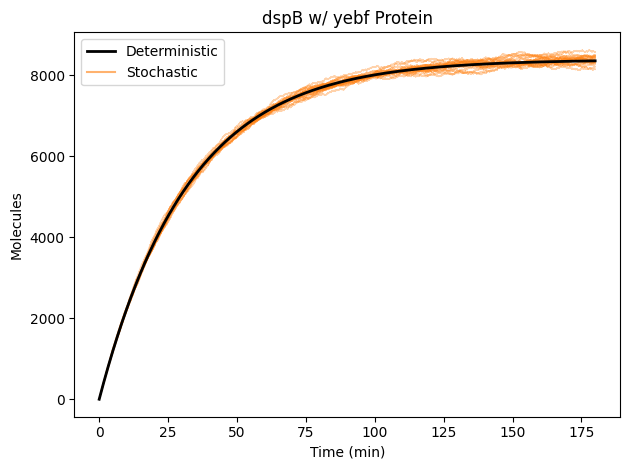

In [ ]:
# Code for dspB
import numpy as np
import matplotlib.pyplot as plt

# ---- Parameters ----
k_syn_dspB = 260
gamma_dspB = 0.031

# ---- Deterministic (Euler) ----
time = 180
delta_t = 0.01
time_vec = np.arange(0, time, delta_t)
n_step = np.size(time_vec)

dspB = np.zeros(n_step)

for i in range(n_step - 1):

  ddspB_dt = k_syn_dspB - gamma_dspB*dspB[i]

  dspB[i+1] = dspB[i] + ddspB_dt*delta_t
print(f"Final dspB_y protein count (deterministic): {np.round(dspB[n_step-1],2)} copies")

# ---- Stochastic (Gillespie) ----
def gillespie(dspb_prot=0, max_step=500000, t_stop=time):
  t = 0
  prot_dspb = dspb_prot

  t_vals   = [t]
  prot_vals = [prot_dspb]

  for step in range(max_step):
    a1 = k_syn_dspB
    a2 = gamma_dspB*prot_dspb
    a  = [a1, a2]
    a0 = np.sum(a)

    if a0 == 0:
      break

    r1 = np.random.rand()
    r2 = np.random.rand()
    tau = -np.log(r1)/a0
    t += tau
    if t > t_stop:
      break
    t_vals.append(t)

    r_mod = r2*a0
    next_reaction_idx = -1
    cumulative_rate = 0
    for i, ai in enumerate(a):
      cumulative_rate += ai
      if r_mod < cumulative_rate:
        next_reaction_idx = i
        break

    if next_reaction_idx == 0:
      prot_dspb += 1
    elif next_reaction_idx == 1:
      prot_dspb -= 1

    prot_dspb = max(prot_dspb, 0)

    prot_vals.append(prot_dspb)

  return t_vals, prot_vals

# ---- Run Gillespie and overlay on the deterministic solution ----
runs = 20

for i in range(runs):
  t_vals, prot_vals = gillespie()
  plt.plot(t_vals, prot_vals, color='tab:orange', alpha=0.35, lw=0.8)

# Deterministic curves on top (bold black)
plt.plot(time_vec, dspB, 'k', lw=2, label='Deterministic')

# Proxy handles so the legend labels the stochastic runs
plt.plot([], [], color='tab:orange', alpha=0.6, label='Stochastic')
plt.title('dspB w/ yebf Protein')
plt.xlabel('Time (min)')
plt.ylabel('Molecules')
plt.legend()
plt.tight_layout()
plt.show()

Final sspa protein count (deterministic): 10408.14 copies


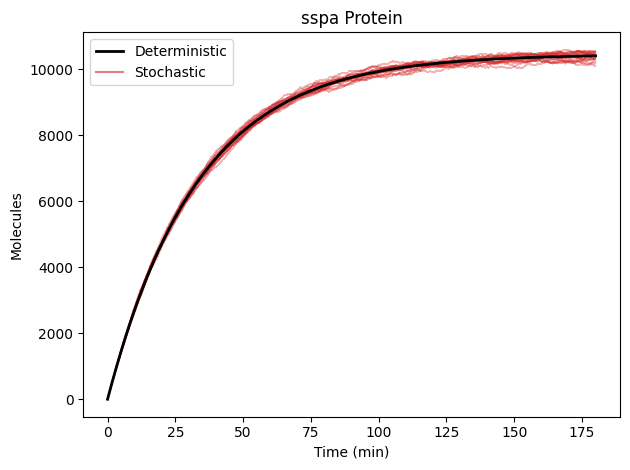

In [ ]:
# Code for sspa
import numpy as np
import matplotlib.pyplot as plt

# ---- Parameters ----
k_syn_sspa = 313.66 # can change to 261.44 if translation rate was 10/min
gamma_sspa = 0.03

# ---- Deterministic (Euler) ----
time = 180
delta_t = 0.01
time_vec = np.arange(0, time, delta_t)
n_step = np.size(time_vec)

sspa = np.zeros(n_step)

for i in range(n_step - 1):

  dsspa_dt = k_syn_sspa - gamma_sspa*sspa[i]

  sspa[i+1] = sspa[i] + dsspa_dt*delta_t

print(f"Final sspa protein count (deterministic): {np.round(sspa[n_step-1],2)} copies")

# ---- Stochastic (Gillespie) ----
def gillespie(sspa_prot=0, max_step=500000, t_stop=time):
  t = 0
  prot_sspa = sspa_prot

  t_vals   = [t]
  prot_vals = [prot_sspa]

  for step in range(max_step):
    a1 = k_syn_sspa
    a2 = gamma_sspa*prot_sspa
    a  = [a1, a2]
    a0 = np.sum(a)

    if a0 == 0:
      break

    r1 = np.random.rand()
    r2 = np.random.rand()
    tau = -np.log(r1)/a0
    t += tau
    if t > t_stop:
      break
    t_vals.append(t)

    r_mod = r2*a0
    next_reaction_idx = -1
    cumulative_rate = 0
    for i, ai in enumerate(a):
      cumulative_rate += ai
      if r_mod < cumulative_rate:
        next_reaction_idx = i
        break

    if next_reaction_idx == 0:
      prot_sspa += 1
    elif next_reaction_idx == 1:
      prot_sspa -= 1

    prot_sspa = max(prot_sspa, 0)
    prot_vals.append(prot_sspa)

  return t_vals, prot_vals

# ---- Run Gillespie and overlay on the deterministic solution ----
runs = 20

for i in range(runs):
  t_vals, prot_vals = gillespie()
  plt.plot(t_vals, prot_vals, color='tab:red', alpha=0.35, lw=0.8)

# Deterministic curves on top (bold black)
plt.plot(time_vec, sspa, 'k', lw=2, label='Deterministic')

# Proxy handles so the legend labels the stochastic runs
plt.plot([], [], color='tab:red', alpha=0.6, label='Stochastic')
plt.title('sspa Protein')
plt.xlabel('Time (min)')
plt.ylabel('Molecules')
plt.legend()
plt.tight_layout()
plt.show()